# AgriVision AI — Complete modular Colab workflow
**An Explainable Deep Learning-Based Multi-Crop Plant Disease Detection and Classification System**

Develop in VS Code → push code to GitHub → clone here → upload real PlantVillage
data to Drive → audit → train both architectures → evaluate → explain → demo.

Select **Runtime → Change runtime type → T4 GPU** when available. Run cells in order.
See `docs/COLAB_GUIDE.md` for troubleshooting and reconnection instructions.
This notebook imports project modules and never rewrites them. No output, accuracy
or screenshot has been pre-filled. Free Colab GPU access is not guaranteed.

In [1]:
import tensorflow as tf
import pandas as pd
import numpy as np
import os

# Configuration
IMG_SIZE = 224
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

# Google Drive paths
METADATA_DIR = "/content/drive/MyDrive/AgriVision-AI/datasets/metadata"

# Load saved manifests
train_df = pd.read_csv(
    os.path.join(METADATA_DIR, "train_manifest.csv")
)

val_df = pd.read_csv(
    os.path.join(METADATA_DIR, "validation_manifest.csv")
)

test_df = pd.read_csv(
    os.path.join(METADATA_DIR, "test_manifest.csv")
)

# Restore class mapping
CLASS_NAMES = sorted(train_df["class_name"].unique())
NUM_CLASSES = len(CLASS_NAMES)

class_to_index = {
    name: index
    for index, name in enumerate(CLASS_NAMES)
}

# Image loading
def load_image(filepath, label):

    image = tf.io.read_file(filepath)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )

    image = tf.cast(image, tf.float32)

    return image, label


# Dataset creation
def create_dataset(dataframe, training=False):

    paths = dataframe["filepath"].values

    labels = dataframe["class_name"].map(
        class_to_index
    ).values.astype(np.int32)

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            len(dataframe),
            seed=42,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


# Restore all datasets
train_ds = create_dataset(train_df, training=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

print("DATASETS RESTORED SUCCESSFULLY!")
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))
print("Number of classes:", NUM_CLASSES)

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/AgriVision-AI/datasets/metadata/train_manifest.csv'

In [2]:
import os

PROJECT_DIR = "/content/gdrive/MyDrive/AgriVision-AI"

DATASET_DIR = os.path.join(
    PROJECT_DIR, "datasets/PlantVillage/PlantVillage"
)

METADATA_DIR = os.path.join(
    PROJECT_DIR, "datasets/metadata"
)

os.makedirs(METADATA_DIR, exist_ok=True)

print("Dataset exists:", os.path.exists(DATASET_DIR))
print("Metadata directory exists:", os.path.exists(METADATA_DIR))

print("\nMetadata files:")
print(os.listdir(METADATA_DIR))

print("\nDataset classes:", len([
    d for d in os.listdir(DATASET_DIR)
    if os.path.isdir(os.path.join(DATASET_DIR, d))
]))

Dataset exists: False
Metadata directory exists: True

Metadata files:
[]


FileNotFoundError: [Errno 2] No such file or directory: '/content/gdrive/MyDrive/AgriVision-AI/datasets/PlantVillage/PlantVillage'

In [3]:
import os

print("========== CONTENT DIRECTORY ==========")
print(os.listdir("/content"))

print("\n========== POSSIBLE DRIVE MOUNTS ==========")

for path in ["/content/drive", "/content/gdrive"]:
    print(f"\nChecking: {path}")
    print("Exists:", os.path.exists(path))

    if os.path.exists(path):
        print("Contents:", os.listdir(path)[:20])

print("\n========== SEARCHING FOR AGRIVISION-AI ==========")

search_roots = ["/content/drive", "/content/gdrive"]

for root in search_roots:
    if os.path.exists(root):
        for current, dirs, files in os.walk(root):
            dirs[:] = [d for d in dirs if d not in [".Trash", ".cache"]]

            if "AgriVision-AI" in dirs:
                print("PROJECT FOUND:", os.path.join(current, "AgriVision-AI"))
                dirs.remove("AgriVision-AI")

========== CONTENT DIRECTORY ==========
['.config', 'gdrive', 'sample_data']

========== POSSIBLE DRIVE MOUNTS ==========

Checking: /content/drive
Exists: False

Checking: /content/gdrive
Exists: True
Contents: ['MyDrive']

========== SEARCHING FOR AGRIVISION-AI ==========
PROJECT FOUND: /content/gdrive/MyDrive/AgriVision-AI


In [4]:
import os

PROJECT_DIR = "/content/gdrive/MyDrive/AgriVision-AI"

print("PROJECT FOLDERS:")
for item in os.listdir(PROJECT_DIR):
    path = os.path.join(PROJECT_DIR, item)

    if os.path.isdir(path):
        print(f"\n📁 {item}/")

        for subitem in os.listdir(path)[:30]:
            subpath = os.path.join(path, subitem)

            if os.path.isdir(subpath):
                print(f"   📁 {subitem}/")
            else:
                print(f"   📄 {subitem}")

PROJECT FOLDERS:

📁 datasets/
   📁 metadata/


In [5]:
import os

search_paths = [
    "/content/gdrive/MyDrive",
    "/root/.cache/kagglehub/datasets/emmarex/plantdisease/versions"
]

for root in search_paths:
    print(f"\n========== SEARCHING: {root} ==========")

    if not os.path.exists(root):
        print("Path does not exist.")
        continue

    for current, dirs, files in os.walk(root):
        dirs[:] = [d for d in dirs if d not in [".Trash", ".cache"]]

        if os.path.basename(current).lower() == "plantvillage":
            print("FOUND:", current)
            print("Subfolders:", dirs[:20])

        if "PlantVillage" in dirs:
            print("FOUND:", os.path.join(current, "PlantVillage"))


========== SEARCHING: /content/gdrive/MyDrive ==========

========== SEARCHING: /root/.cache/kagglehub/datasets/emmarex/plantdisease/versions ==========
Path does not exist.


In [6]:
!pip install -q kagglehub

import os
import kagglehub

print("KaggleHub version:", kagglehub.__version__)

# Check Colab secrets
from google.colab import userdata

try:
    token = userdata.get("KAGGLE_API_TOKEN")
    print("Kaggle API token available:", bool(token))
except Exception as e:
    print("Kaggle API token unavailable:", str(e))

KaggleHub version: 1.0.3
Kaggle API token available: True


In [7]:
!pip install -q kagglehub

import os
import kagglehub

print("KaggleHub version:", kagglehub.__version__)

# Check Colab secrets
from google.colab import userdata

try:
    token = userdata.get("KAGGLE_API_TOKEN")
    print("Kaggle API token available:", bool(token))
except Exception as e:
    print("Kaggle API token unavailable:", str(e))

KaggleHub version: 1.0.3
Kaggle API token available: True


In [8]:
import os
import kagglehub

from google.colab import userdata

# Restore Kaggle authentication
os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

# Download the original dataset
print("Starting PlantVillage download...")

DATASET_DOWNLOAD_PATH = kagglehub.dataset_download(
    "emmarex/plantdisease"
)

print("\nDownload completed!")
print("Dataset location:", DATASET_DOWNLOAD_PATH)

# Inspect downloaded folders
print("\nDownloaded directory structure:")

for item in os.listdir(DATASET_DOWNLOAD_PATH):
    path = os.path.join(DATASET_DOWNLOAD_PATH, item)

    if os.path.isdir(path):
        print(f"📁 {item}/")

Starting PlantVillage download...
Using Colab cache for faster access to the 'plantdisease' dataset.

Download completed!
Dataset location: /kaggle/input/plantdisease

Downloaded directory structure:
📁 PlantVillage/
📁 plantvillage/


In [9]:
import os
import shutil

# Source: correct Kaggle dataset directory
SOURCE_DIR = "/kaggle/input/plantdisease/PlantVillage"

# Destination: AgriVision-AI project
PROJECT_DIR = "/content/gdrive/MyDrive/AgriVision-AI"

TARGET_DIR = os.path.join(
    PROJECT_DIR, "datasets/PlantVillage/PlantVillage"
)

os.makedirs(os.path.dirname(TARGET_DIR), exist_ok=True)

# Verify source
assert os.path.isdir(SOURCE_DIR), "Source dataset not found!"

# Copy only the correct PlantVillage directory
if not os.path.exists(TARGET_DIR):
    print("Copying PlantVillage to Google Drive...")
    shutil.copytree(SOURCE_DIR, TARGET_DIR)
else:
    print("Destination already exists. Skipping copy.")

print("\nDataset restoration completed!")
print("Source:", SOURCE_DIR)
print("Destination:", TARGET_DIR)

Copying PlantVillage to Google Drive...

Dataset restoration completed!
Source: /kaggle/input/plantdisease/PlantVillage
Destination: /content/gdrive/MyDrive/AgriVision-AI/datasets/PlantVillage/PlantVillage


In [10]:
import os
import pandas as pd

TARGET_DIR = "/content/gdrive/MyDrive/AgriVision-AI/datasets/PlantVillage/PlantVillage"

class_counts = {}

for class_name in sorted(os.listdir(TARGET_DIR)):
    class_path = os.path.join(TARGET_DIR, class_name)

    if os.path.isdir(class_path):
        images = [
            f for f in os.listdir(class_path)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ]

        class_counts[class_name] = len(images)

# Display as table
distribution_df = pd.DataFrame(
    list(class_counts.items()),
    columns=["Disease Class", "Image Count"]
)

print("========== DATASET VERIFICATION ==========")
print("Total classes:", len(class_counts))
print("Total images:", sum(class_counts.values()))

display(distribution_df)

assert len(class_counts) == 15, "Expected 15 classes!"
assert sum(class_counts.values()) == 20638, "Image count mismatch!"

print("\nSUCCESS: Dataset verification passed!")

========== DATASET VERIFICATION ==========
Total classes: 15
Total images: 20638


,Disease Class,Image Count
0,Pepper__bell___Bacterial_spot,997
1,Pepper__bell___healthy,1478
2,Potato___Early_blight,1000
3,Potato___Late_blight,1000
4,Potato___healthy,152
5,Tomato_Bacterial_spot,2127
6,Tomato_Early_blight,1000
7,Tomato_Late_blight,1909
8,Tomato_Leaf_Mold,952
9,Tomato_Septoria_leaf_spot,1771



SUCCESS: Dataset verification passed!


In [11]:
import os
import hashlib
import pandas as pd

DATASET_DIR = "/content/gdrive/MyDrive/AgriVision-AI/datasets/PlantVillage/PlantVillage"

METADATA_DIR = "/content/gdrive/MyDrive/AgriVision-AI/datasets/metadata"
os.makedirs(METADATA_DIR, exist_ok=True)

records = []
seen_hashes = set()

total_scanned = 0

print("Starting duplicate detection...")

for class_name in sorted(os.listdir(DATASET_DIR)):

    class_path = os.path.join(DATASET_DIR, class_name)

    if not os.path.isdir(class_path):
        continue

    for filename in sorted(os.listdir(class_path)):

        filepath = os.path.join(class_path, filename)

        if not os.path.isfile(filepath):
            continue

        if not filename.lower().endswith((".jpg", ".jpeg", ".png")):
            continue

        total_scanned += 1

        sha256 = hashlib.sha256()

        with open(filepath, "rb") as f:
            for chunk in iter(lambda: f.read(1024 * 1024), b""):
                sha256.update(chunk)

        image_hash = sha256.hexdigest()

        if image_hash not in seen_hashes:

            seen_hashes.add(image_hash)

            records.append({
                "filepath": filepath,
                "class_name": class_name,
                "sha256": image_hash
            })

clean_df = pd.DataFrame(records)

CLEAN_MANIFEST = os.path.join(
    METADATA_DIR,
    "plantvillage_clean_manifest.csv"
)

clean_df.to_csv(CLEAN_MANIFEST, index=False)

print("\n========== CLEANING REPORT ==========")
print("Total images scanned:", total_scanned)
print("Unique images:", len(clean_df))
print("Duplicate copies:", total_scanned - len(clean_df))
print("Total classes:", clean_df["class_name"].nunique())
print("Manifest saved:", CLEAN_MANIFEST)

print("\nClass distribution:")
print(clean_df["class_name"].value_counts().sort_index())

assert total_scanned == 20638
assert clean_df["class_name"].nunique() == 15

print("\nSUCCESS: Clean manifest generated!")

Starting duplicate detection...

========== CLEANING REPORT ==========
Total images scanned: 20638
Unique images: 20624
Duplicate copies: 14
Total classes: 15
Manifest saved: /content/gdrive/MyDrive/AgriVision-AI/datasets/metadata/plantvillage_clean_manifest.csv

Class distribution:
class_name
Pepper__bell___Bacterial_spot                   997
Pepper__bell___healthy                         1478
Potato___Early_blight                          1000
Potato___Late_blight                           1000
Potato___healthy                                152
Tomato_Bacterial_spot                          2127
Tomato_Early_blight                            1000
Tomato_Late_blight                             1901
Tomato_Leaf_Mold                                952
Tomato_Septoria_leaf_spot                      1771
Tomato_Spider_mites_Two_spotted_spider_mite    1676
Tomato__Target_Spot                            1404
Tomato__Tomato_YellowLeaf__Curl_Virus          3208
Tomato__Tomato_mosaic_virus  

In [12]:
import os
import json
import pandas as pd
from sklearn.model_selection import train_test_split

# Paths
METADATA_DIR = "/content/gdrive/MyDrive/AgriVision-AI/datasets/metadata"

CLEAN_MANIFEST = os.path.join(
    METADATA_DIR, "plantvillage_clean_manifest.csv"
)

# Load clean dataset
clean_df = pd.read_csv(CLEAN_MANIFEST)

# First split: 70% training, 30% temporary
train_df, temp_df = train_test_split(
    clean_df,
    test_size=0.30,
    random_state=42,
    stratify=clean_df["class_name"]
)

# Second split: divide remaining 30% equally
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["class_name"]
)

# Save manifests
train_df.to_csv(
    os.path.join(METADATA_DIR, "train_manifest.csv"),
    index=False
)

val_df.to_csv(
    os.path.join(METADATA_DIR, "validation_manifest.csv"),
    index=False
)

test_df.to_csv(
    os.path.join(METADATA_DIR, "test_manifest.csv"),
    index=False
)

# Create consistent class mapping
class_names = sorted(clean_df["class_name"].unique())

class_mapping = {
    name: index for index, name in enumerate(class_names)
}

with open(
    os.path.join(METADATA_DIR, "class_mapping.json"), "w"
) as f:
    json.dump(class_mapping, f, indent=4)

# Verify no overlapping image paths
train_paths = set(train_df["filepath"])
val_paths = set(val_df["filepath"])
test_paths = set(test_df["filepath"])

assert not (train_paths & val_paths)
assert not (train_paths & test_paths)
assert not (val_paths & test_paths)

assert len(train_df) + len(val_df) + len(test_df) == len(clean_df)

# Results
print("========== DATASET SPLIT REPORT ==========")

print(f"Training images:   {len(train_df)} ({len(train_df)/len(clean_df)*100:.2f}%)")
print(f"Validation images: {len(val_df)} ({len(val_df)/len(clean_df)*100:.2f}%)")
print(f"Testing images:    {len(test_df)} ({len(test_df)/len(clean_df)*100:.2f}%)")

print("\nTotal images:", len(clean_df))
print("Total classes:", len(class_names))

print("\nClass mapping:")
print(class_mapping)

print("\nOverlap verification:")
print("Train ∩ Validation:", len(train_paths & val_paths))
print("Train ∩ Test:", len(train_paths & test_paths))
print("Validation ∩ Test:", len(val_paths & test_paths))

print("\nSUCCESS: All three manifests saved and verified!")

========== DATASET SPLIT REPORT ==========
Training images:   14436 (70.00%)
Validation images: 3094 (15.00%)
Testing images:    3094 (15.00%)

Total images: 20624
Total classes: 15

Class mapping:
{'Pepper__bell___Bacterial_spot': 0, 'Pepper__bell___healthy': 1, 'Potato___Early_blight': 2, 'Potato___Late_blight': 3, 'Potato___healthy': 4, 'Tomato_Bacterial_spot': 5, 'Tomato_Early_blight': 6, 'Tomato_Late_blight': 7, 'Tomato_Leaf_Mold': 8, 'Tomato_Septoria_leaf_spot': 9, 'Tomato_Spider_mites_Two_spotted_spider_mite': 10, 'Tomato__Target_Spot': 11, 'Tomato__Tomato_YellowLeaf__Curl_Virus': 12, 'Tomato__Tomato_mosaic_virus': 13, 'Tomato_healthy': 14}

Overlap verification:
Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0

SUCCESS: All three manifests saved and verified!


In [13]:
import tensorflow as tf
from tensorflow.keras import mixed_precision

# Check GPU
gpus = tf.config.list_physical_devices("GPU")

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", gpus)

assert len(gpus) > 0, "GPU not detected! Enable GPU in Colab."

# Enable mixed precision
mixed_precision.set_global_policy("mixed_float16")

print("\nMixed precision policy:", mixed_precision.global_policy())

print("\nGPU configuration successful!")

TensorFlow version: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

Mixed precision policy: <DTypePolicy "mixed_float16">

GPU configuration successful!


In [14]:
import os
import pandas as pd
import tensorflow as tf

# Project paths
PROJECT_DIR = "/content/gdrive/MyDrive/AgriVision-AI"
METADATA_DIR = os.path.join(PROJECT_DIR, "datasets/metadata")

# Load manifests
train_df = pd.read_csv(os.path.join(METADATA_DIR, "train_manifest.csv"))
val_df = pd.read_csv(os.path.join(METADATA_DIR, "validation_manifest.csv"))
test_df = pd.read_csv(os.path.join(METADATA_DIR, "test_manifest.csv"))

# Configuration
IMG_SIZE = 224
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

# Class mapping
class_names = sorted(train_df["class_name"].unique())
NUM_CLASSES = len(class_names)

class_to_index = {
    name: index for index, name in enumerate(class_names)
}

print("Classes:", NUM_CLASSES)
print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

# Image loading function
def load_image(filepath, label):

    image = tf.io.read_file(filepath)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )

    image = tf.cast(image, tf.float32)

    return image, label


# Dataset creation function
def create_dataset(dataframe, training=False):

    paths = dataframe["filepath"].values

    labels = dataframe["class_name"].map(
        class_to_index
    ).values

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=42,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


# Build datasets
train_ds = create_dataset(train_df, training=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

print("\nTensorFlow datasets created successfully!")

Classes: 15
Image size: 224
Batch size: 32

TensorFlow datasets created successfully!


In [15]:
for images, labels in train_ds.take(1):

    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Image dtype:", images.dtype)
    print("Pixel minimum:", tf.reduce_min(images).numpy())
    print("Pixel maximum:", tf.reduce_max(images).numpy())

print("\nTraining batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Testing batches:", tf.data.experimental.cardinality(test_ds).numpy())

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Image dtype: <dtype: 'float32'>
Pixel minimum: 0.0
Pixel maximum: 255.0

Training batches: 452
Validation batches: 97
Testing batches: 97


In [16]:
import os
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.callbacks import ModelCheckpoint

# Model directories
PROJECT_DIR = "/content/gdrive/MyDrive/AgriVision-AI"

MODEL_DIR = os.path.join(PROJECT_DIR, "models")
CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

# Model paths
BEST_MODEL_PATH = os.path.join(
    MODEL_DIR, "efficientnetb0_best.keras"
)

# Verify Google Drive write access
test_path = os.path.join(MODEL_DIR, "write_test.txt")

with open(test_path, "w") as f:
    f.write("Google Drive checkpoint storage verified.")

assert os.path.exists(test_path)

# Load pretrained EfficientNetB0
base_model = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained backbone
base_model.trainable = False

# Build classification architecture
inputs = keras.Input(shape=(224, 224, 3))

x = base_model(inputs, training=False)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    dtype="float32",
    name="classification_head"
)(x)

efficientnet_model = keras.Model(
    inputs,
    outputs,
    name="AgriVision_EfficientNetB0"
)

# Compile
efficientnet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Model summary
efficientnet_model.summary()

print("\nBackbone trainable:", base_model.trainable)
print("Number of classes:", NUM_CLASSES)
print("Checkpoint destination:", BEST_MODEL_PATH)
print("Google Drive write access: verified")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "AgriVision_EfficientNetB0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classification_head (Dense)     │ (None, 15)             │        19,215 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,068,786 (15.52 MB)

 Trainable params: 19,215 (75.06 KB)

 Non-trainable params: 4,049,571 (15.45 MB)


Backbone trainable: False
Number of classes: 15
Checkpoint destination: /content/gdrive/MyDrive/AgriVision-AI/models/efficientnetb0_best.keras
Google Drive write access: verified


In [17]:
import os
import tensorflow as tf
from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    ReduceLROnPlateau,
    BackupAndRestore
)

MODEL_DIR = "/content/gdrive/MyDrive/AgriVision-AI/models"
CHECKPOINT_DIR = "/content/gdrive/MyDrive/AgriVision-AI/checkpoints"

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

BEST_MODEL_PATH = os.path.join(
    MODEL_DIR, "efficientnetb0_best.keras"
)

BACKUP_DIR = os.path.join(
    CHECKPOINT_DIR, "efficientnetb0_phase1_backup"
)

callbacks = [

    ModelCheckpoint(
        filepath=BEST_MODEL_PATH,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),

    BackupAndRestore(
        backup_dir=BACKUP_DIR
    ),

    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

print("Checkpoint configuration completed!")
print("Best model:", BEST_MODEL_PATH)
print("Training backup:", BACKUP_DIR)

Checkpoint configuration completed!
Best model: /content/gdrive/MyDrive/AgriVision-AI/models/efficientnetb0_best.keras
Training backup: /content/gdrive/MyDrive/AgriVision-AI/checkpoints/efficientnetb0_phase1_backup


In [18]:
EPOCHS_PHASE1 = 15

history_phase1 = efficientnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_PHASE1,
    callbacks=callbacks,
    verbose=1
)

# Explicitly save the final in-memory model
LATEST_MODEL_PATH = os.path.join(
    MODEL_DIR, "efficientnetb0_latest.keras"
)

efficientnet_model.save(LATEST_MODEL_PATH)

print("\n========== PHASE 1 COMPLETE ==========")
print("Latest model:", LATEST_MODEL_PATH)
print("Best model:", BEST_MODEL_PATH)

Epoch 1/15
452/452 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step - accuracy: 0.5843 - loss: 1.4559
Epoch 1: val_accuracy improved from None to 0.87686, saving model to /content/gdrive/MyDrive/AgriVision-AI/models/efficientnetb0_best.keras

Epoch 1: finished saving model to /content/gdrive/MyDrive/AgriVision-AI/models/efficientnetb0_best.keras
452/452 ━━━━━━━━━━━━━━━━━━━━ 127s 185ms/step - accuracy: 0.7412 - loss: 0.9594 - val_accuracy: 0.8769 - val_loss: 0.4718 - learning_rate: 0.0010
Epoch 2/15
451/452 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.8763 - loss: 0.4623
Epoch 2: val_accuracy improved from 0.87686 to 0.91015, saving model to /content/gdrive/MyDrive/AgriVision-AI/models/efficientnetb0_best.keras

Epoch 2: finished saving model to /content/gdrive/MyDrive/AgriVision-AI/models/efficientnetb0_best.keras
452/452 ━━━━━━━━━━━━━━━━━━━━ 22s 48ms/step - accuracy: 0.8829 - loss: 0.4343 - val_accuracy: 0.9101 - val_loss: 0.3261 - learning_rate: 0.0010
Epoch 3/15
452/452 ━━━━━━━━━━━━━━━━━━━━ 0s 

In [19]:
import os

MODEL_DIR = "/content/gdrive/MyDrive/AgriVision-AI/models"

model_files = [
    "efficientnetb0_best.keras",
    "efficientnetb0_latest.keras"
]

print("========== CHECKPOINT VERIFICATION ==========")

for filename in model_files:

    path = os.path.join(MODEL_DIR, filename)

    if os.path.exists(path):

        size_mb = os.path.getsize(path) / (1024 * 1024)

        print(f"\n{filename}")
        print(f"Status: SAVED")
        print(f"Size: {size_mb:.2f} MB")

    else:
        print(f"\nERROR: {filename} NOT FOUND")
        raise FileNotFoundError(path)

print("\nSUCCESS: Both model checkpoints are available!")

========== CHECKPOINT VERIFICATION ==========

efficientnetb0_best.keras
Status: SAVED
Size: 16.63 MB

efficientnetb0_latest.keras
Status: SAVED
Size: 16.63 MB

SUCCESS: Both model checkpoints are available!


In [20]:
import tensorflow as tf
from tensorflow import keras

# Load the best Phase 1 checkpoint
BEST_MODEL_PATH = (
    "/content/gdrive/MyDrive/AgriVision-AI/models/"
    "efficientnetb0_best.keras"
)

efficientnet_model = keras.models.load_model(
    BEST_MODEL_PATH
)

# Access EfficientNetB0 backbone
base_model = efficientnet_model.get_layer("efficientnetb0")

# Unfreeze backbone
base_model.trainable = True

# Freeze all except last 30 layers
FINE_TUNE_LAYERS = 30

for layer in base_model.layers[:-FINE_TUNE_LAYERS]:
    layer.trainable = False

# Keep BatchNormalization layers frozen
for layer in base_model.layers:
    if isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False

# Recompile with lower learning rate
efficientnet_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display configuration
trainable_params = sum(
    tf.keras.backend.count_params(w)
    for w in efficientnet_model.trainable_weights
)

total_params = efficientnet_model.count_params()

print("========== FINE-TUNING CONFIGURATION ==========")
print("Total backbone layers:", len(base_model.layers))
print("Trainable backbone layers:", sum(
    layer.trainable for layer in base_model.layers
))
print("Trainable parameters:", trainable_params)
print("Total parameters:", total_params)
print("Learning rate: 0.00001")
print("BatchNormalization: Frozen")
print("\nFine-tuning configuration successful!")

========== FINE-TUNING CONFIGURATION ==========
Total backbone layers: 238
Trainable backbone layers: 23
Trainable parameters: 1502575
Total parameters: 4068786
Learning rate: 0.00001
BatchNormalization: Frozen

Fine-tuning configuration successful!


In [21]:
import os
import tensorflow as tf
from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    ReduceLROnPlateau,
    BackupAndRestore
)

MODEL_DIR = "/content/gdrive/MyDrive/AgriVision-AI/models"
CHECKPOINT_DIR = "/content/gdrive/MyDrive/AgriVision-AI/checkpoints"

FINE_TUNED_MODEL_PATH = os.path.join(
    MODEL_DIR, "efficientnetb0_finetuned_best.keras"
)

fine_tune_callbacks = [

    ModelCheckpoint(
        filepath=FINE_TUNED_MODEL_PATH,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),

    BackupAndRestore(
        backup_dir=os.path.join(
            CHECKPOINT_DIR,
            "efficientnetb0_phase2_backup"
        )
    ),

    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

print("Fine-tuning callbacks configured.")
print("Best fine-tuned model:", FINE_TUNED_MODEL_PATH)

Fine-tuning callbacks configured.
Best fine-tuned model: /content/gdrive/MyDrive/AgriVision-AI/models/efficientnetb0_finetuned_best.keras


In [22]:
history_finetune = efficientnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=fine_tune_callbacks,
    verbose=1
)

# Save final fine-tuned model separately
LATEST_FINE_TUNED_PATH = os.path.join(
    MODEL_DIR, "efficientnetb0_finetuned_latest.keras"
)

efficientnet_model.save(LATEST_FINE_TUNED_PATH)

print("\n========== PHASE 2 COMPLETE ==========")
print("Best model:", FINE_TUNED_MODEL_PATH)
print("Latest model:", LATEST_FINE_TUNED_PATH)

Epoch 1/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - accuracy: 0.9536 - loss: 0.1455
Epoch 1: val_accuracy improved from None to 0.96412, saving model to /content/gdrive/MyDrive/AgriVision-AI/models/efficientnetb0_finetuned_best.keras

Epoch 1: finished saving model to /content/gdrive/MyDrive/AgriVision-AI/models/efficientnetb0_finetuned_best.keras
452/452 ━━━━━━━━━━━━━━━━━━━━ 99s 130ms/step - accuracy: 0.9549 - loss: 0.1357 - val_accuracy: 0.9641 - val_loss: 0.1159 - learning_rate: 1.0000e-05
Epoch 2/10
450/452 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.9592 - loss: 0.1203
Epoch 2: val_accuracy improved from 0.96412 to 0.96671, saving model to /content/gdrive/MyDrive/AgriVision-AI/models/efficientnetb0_finetuned_best.keras

Epoch 2: finished saving model to /content/gdrive/MyDrive/AgriVision-AI/models/efficientnetb0_finetuned_best.keras
452/452 ━━━━━━━━━━━━━━━━━━━━ 20s 43ms/step - accuracy: 0.9616 - loss: 0.1178 - val_accuracy: 0.9667 - val_loss: 0.1066 - learning_rate: 1.0000e

In [23]:
import os
import tensorflow as tf
from tensorflow import keras

MODEL_DIR = "/content/gdrive/MyDrive/AgriVision-AI/models"

BEST_FINETUNED_PATH = os.path.join(
    MODEL_DIR,
    "efficientnetb0_finetuned_best.keras"
)

LATEST_FINETUNED_PATH = os.path.join(
    MODEL_DIR,
    "efficientnetb0_finetuned_latest.keras"
)

print("========== MODEL CHECKPOINT VERIFICATION ==========")

for path in [BEST_FINETUNED_PATH, LATEST_FINETUNED_PATH]:

    assert os.path.exists(path), f"Missing checkpoint: {path}"

    size = os.path.getsize(path) / (1024 * 1024)

    print(os.path.basename(path))
    print(f"Size: {size:.2f} MB")
    print("Status: SAVED\n")

# Load best validation-accuracy checkpoint
best_model = keras.models.load_model(BEST_FINETUNED_PATH)

print("Best fine-tuned model loaded successfully!")
print("Input shape:", best_model.input_shape)
print("Output shape:", best_model.output_shape)

========== MODEL CHECKPOINT VERIFICATION ==========
efficientnetb0_finetuned_best.keras
Size: 39.27 MB
Status: SAVED

efficientnetb0_finetuned_latest.keras
Size: 39.27 MB
Status: SAVED

Best fine-tuned model loaded successfully!
Input shape: (None, 224, 224, 3)
Output shape: (None, 15)


In [24]:
import numpy as np
from sklearn.metrics import classification_report, accuracy_score

# Evaluate best fine-tuned model
test_loss, test_accuracy = best_model.evaluate(
    test_ds,
    verbose=1
)

print("\n========== FINAL TEST RESULTS ==========")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

# Generate actual labels
y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

# Generate model predictions
y_prob = best_model.predict(test_ds, verbose=1)

y_pred = np.argmax(y_prob, axis=1)

# Classification metrics
print("\n========== CLASSIFICATION REPORT ==========")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=4
    )
)

print(
    "\nOverall Accuracy:",
    accuracy_score(y_true, y_pred)
)

97/97 ━━━━━━━━━━━━━━━━━━━━ 21s 108ms/step - accuracy: 0.9716 - loss: 0.0890

========== FINAL TEST RESULTS ==========
Test Loss: 0.0890
Test Accuracy: 97.16%
97/97 ━━━━━━━━━━━━━━━━━━━━ 21s 121ms/step

========== CLASSIFICATION REPORT ==========
                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot     0.9933    0.9933    0.9933       150
                     Pepper__bell___healthy     0.9866    1.0000    0.9933       221
                      Potato___Early_blight     0.9933    0.9867    0.9900       150
                       Potato___Late_blight     0.9933    0.9867    0.9900       150
                           Potato___healthy     0.8462    0.9565    0.8980        23
                      Tomato_Bacterial_spot     0.9752    0.9875    0.9813       319
                        Tomato_Early_blight     0.9366    0.8867    0.9110       150
                         Tomato_Late_blight     0.9619    0.9754    0.9686

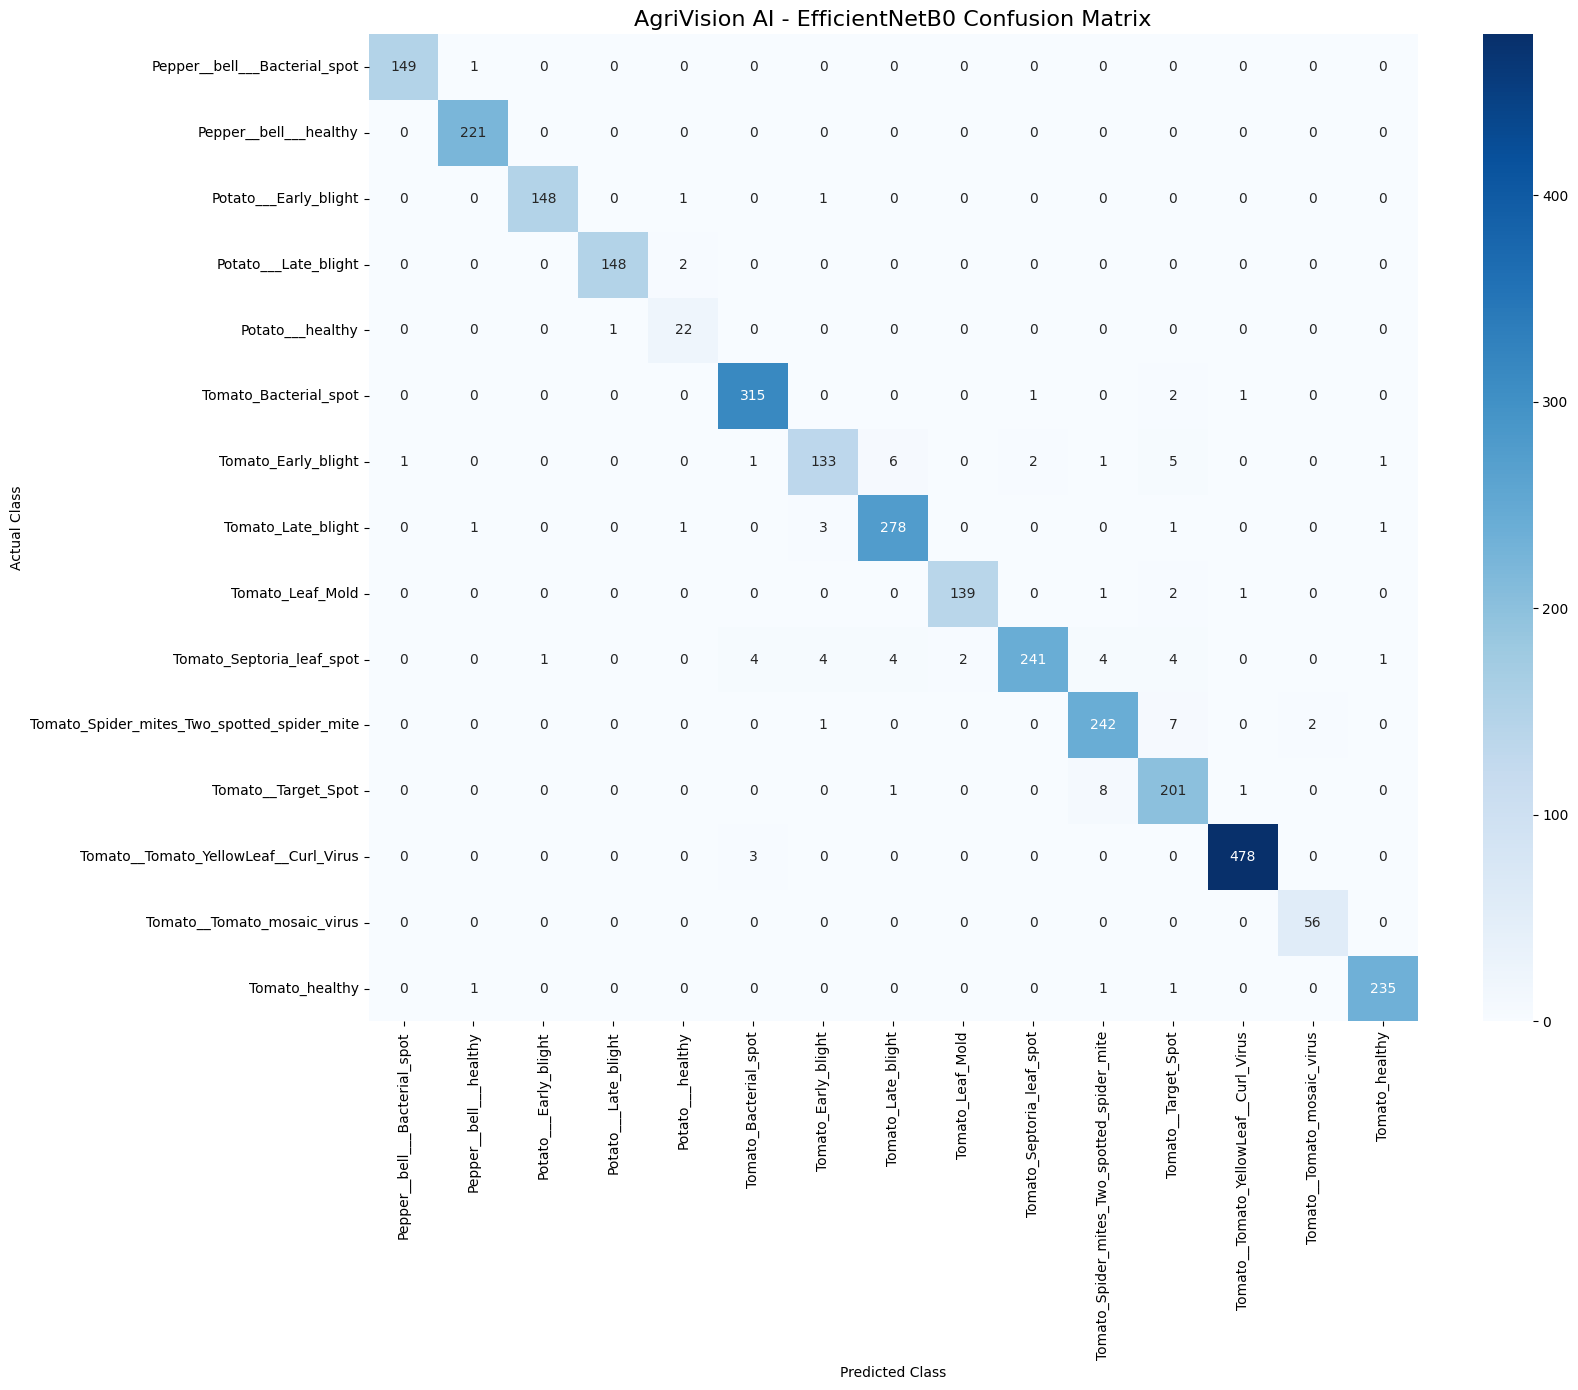

Confusion matrix saved successfully!


In [25]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.metrics import confusion_matrix

# Generate confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Plot
plt.figure(figsize=(17, 14))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title(
    "AgriVision AI - EfficientNetB0 Confusion Matrix",
    fontsize=16
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()

# Save figure
RESULTS_DIR = "/content/gdrive/MyDrive/AgriVision-AI/results"

import os
os.makedirs(RESULTS_DIR, exist_ok=True)

plt.savefig(
    os.path.join(RESULTS_DIR, "efficientnetb0_confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrix saved successfully!")

In [26]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import cv2

from tensorflow import keras

# Use the best fine-tuned model
model = best_model

# Access EfficientNetB0 backbone
base_model = model.get_layer("efficientnetb0")

# Select final convolutional layer
last_conv_layer = base_model.get_layer("top_conv")

print("Selected layer:", last_conv_layer.name)
print("Feature map shape:", last_conv_layer.output.shape)

# Create feature extraction model
feature_model = keras.Model(
    inputs=base_model.input,
    outputs=[
        last_conv_layer.output,
        base_model.output
    ]
)

# Access classification head layers
pooling_layer = model.get_layer("global_average_pooling2d")
dropout_layer = model.get_layer("dropout")
classifier_layer = model.get_layer("classification_head")


def generate_gradcam(image_batch, class_index=None):

    with tf.GradientTape() as tape:

        conv_outputs, features = feature_model(
            image_batch,
            training=False
        )

        x = pooling_layer(features)
        x = dropout_layer(x, training=False)

        predictions = classifier_layer(x)

        if class_index is None:
            class_index = tf.argmax(
                predictions[0]
            )

        class_score = predictions[:, class_index]

    # Calculate gradients
    gradients = tape.gradient(
        class_score,
        conv_outputs
    )

    # Calculate importance weights
    weights = tf.reduce_mean(
        gradients,
        axis=(1, 2)
    )

    # Weighted combination of feature maps
    heatmap = tf.reduce_sum(
        conv_outputs * weights[:, tf.newaxis, tf.newaxis, :],
        axis=-1
    )

    # Apply ReLU
    heatmap = tf.nn.relu(heatmap)

    # Normalize
    heatmap = heatmap[0]

    heatmap = heatmap / (
        tf.reduce_max(heatmap) + keras.backend.epsilon()
    )

    return heatmap.numpy(), predictions.numpy()


print("\nGrad-CAM implementation ready!")

Selected layer: top_conv
Feature map shape: (None, 7, 7, 1280)

Grad-CAM implementation ready!


In [27]:
# Get one test image
for images, labels in test_ds.take(1):
    sample_image = images[0:1]
    actual_label = int(labels[0].numpy())

# Generate Grad-CAM
heatmap, predictions = generate_gradcam(sample_image)

# Predicted class
predicted_index = int(np.argmax(predictions[0]))

confidence = float(predictions[0][predicted_index]) * 100

# Convert original image
original_image = sample_image[0].numpy().astype("uint8")

# Resize heatmap
heatmap_resized = cv2.resize(
    heatmap,
    (224, 224)
)

# Apply color map
heatmap_colored = cv2.applyColorMap(
    np.uint8(255 * heatmap_resized),
    cv2.COLORMAP_JET
)

heatmap_colored = cv2.cvtColor(
    heatmap_colored,
    cv2.COLOR_BGR2RGB
)

# Overlay heatmap on original image
superimposed_image = cv2.addWeighted(
    original_image,
    0.6,
    heatmap_colored,
    0.4,
    0
)

# Display results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original_image)
plt.title("Original Leaf Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap_resized, cmap="jet")
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(superimposed_image)
plt.title("Explainable Prediction")
plt.axis("off")

plt.suptitle(
    f"Predicted: {class_names[predicted_index]}\n"
    f"Actual: {class_names[actual_label]} | "
    f"Confidence: {confidence:.2f}%",
    fontsize=13
)

plt.tight_layout()
plt.show()

error: OpenCV(4.14.0) /io/opencv/modules/imgproc/src/resize.cpp:3892: error: (-215:Assertion failed) func != 0 in function 'resize'


Heatmap shape: (7, 7)
Heatmap dtype: float32


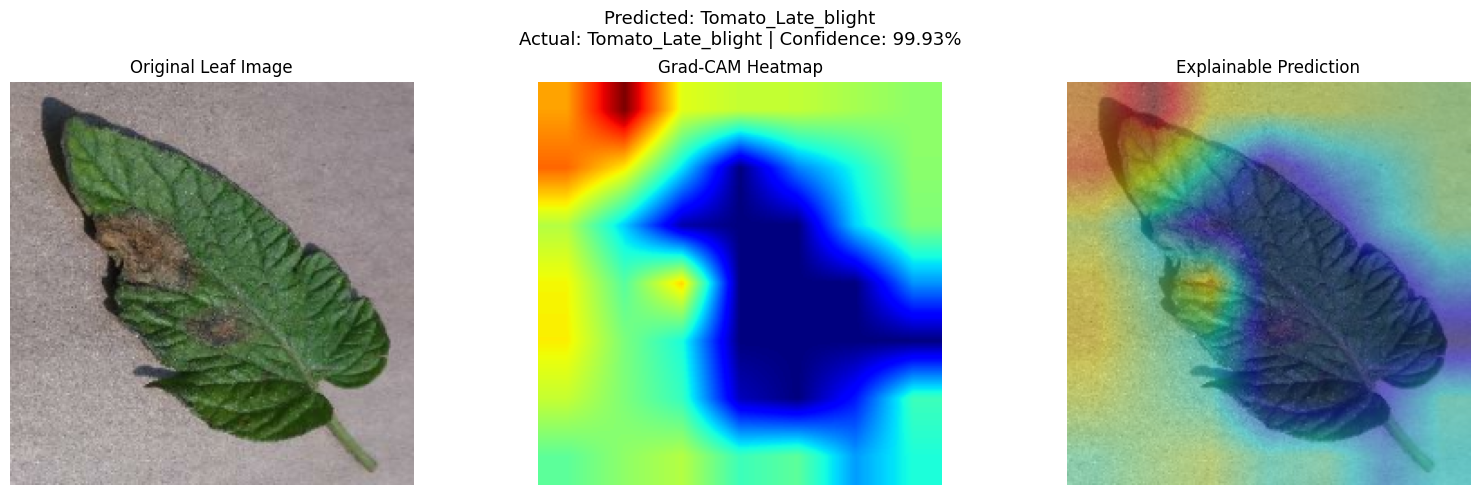


Grad-CAM visualization generated successfully!


In [28]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import tensorflow as tf

# Get one test image
for images, labels in test_ds.take(1):
    sample_image = images[0:1]
    actual_label = int(labels[0].numpy())

# Generate Grad-CAM
heatmap, predictions = generate_gradcam(sample_image)

# Convert heatmap to float32 for OpenCV compatibility
heatmap = np.asarray(heatmap, dtype=np.float32)

# Handle invalid numerical values
heatmap = np.nan_to_num(
    heatmap,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)

# Ensure correct dimensions
heatmap = np.squeeze(heatmap)

print("Heatmap shape:", heatmap.shape)
print("Heatmap dtype:", heatmap.dtype)

# Predicted class
predicted_index = int(np.argmax(predictions[0]))
confidence = float(predictions[0][predicted_index]) * 100

# Original image
original_image = sample_image[0].numpy().astype(np.uint8)

# Resize heatmap
heatmap_resized = cv2.resize(
    heatmap,
    (224, 224),
    interpolation=cv2.INTER_LINEAR
)

# Normalize heatmap
heatmap_resized = np.clip(heatmap_resized, 0, 1)

# Apply color map
heatmap_uint8 = np.uint8(255 * heatmap_resized)

heatmap_colored = cv2.applyColorMap(
    heatmap_uint8,
    cv2.COLORMAP_JET
)

heatmap_colored = cv2.cvtColor(
    heatmap_colored,
    cv2.COLOR_BGR2RGB
)

# Overlay heatmap
superimposed_image = cv2.addWeighted(
    original_image,
    0.6,
    heatmap_colored,
    0.4,
    0
)

# Display
plt.figure(figsize=(16, 5))

plt.subplot(1, 3, 1)
plt.imshow(original_image)
plt.title("Original Leaf Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap_resized, cmap="jet")
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(superimposed_image)
plt.title("Explainable Prediction")
plt.axis("off")

plt.suptitle(
    f"Predicted: {class_names[predicted_index]}\n"
    f"Actual: {class_names[actual_label]} | "
    f"Confidence: {confidence:.2f}%",
    fontsize=13
)

plt.tight_layout()
plt.show()

print("\nGrad-CAM visualization generated successfully!")

In [29]:
import os
import matplotlib.pyplot as plt

RESULTS_DIR = (
    "/content/gdrive/MyDrive/AgriVision-AI/results"
)

os.makedirs(RESULTS_DIR, exist_ok=True)

gradcam_path = os.path.join(
    RESULTS_DIR,
    "efficientnetb0_gradcam.png"
)

plt.imsave(
    gradcam_path,
    superimposed_image
)

print("Grad-CAM saved successfully!")
print("Location:", gradcam_path)

Grad-CAM saved successfully!
Location: /content/gdrive/MyDrive/AgriVision-AI/results/efficientnetb0_gradcam.png


In [30]:
import os
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import MobileNetV3Large

# ==========================================
# 1. PROJECT DIRECTORIES
# ==========================================

PROJECT_DIR = "/content/gdrive/MyDrive/AgriVision-AI"

MODEL_DIR = os.path.join(PROJECT_DIR, "models")
CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

MOBILENET_BEST_PATH = os.path.join(
    MODEL_DIR,
    "mobilenetv3large_best.keras"
)

MOBILENET_LATEST_PATH = os.path.join(
    MODEL_DIR,
    "mobilenetv3large_latest.keras"
)

# ==========================================
# 2. LOAD PRETRAINED MOBILENETV3LARGE
# ==========================================

mobilenet_base = MobileNetV3Large(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3),
    include_preprocessing=True
)

# Freeze pretrained backbone
mobilenet_base.trainable = False

# ==========================================
# 3. BUILD CLASSIFICATION HEAD
# ==========================================

inputs = keras.Input(
    shape=(224, 224, 3),
    name="mobilenet_input"
)

x = mobilenet_base(inputs, training=False)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    dtype="float32",
    name="mobilenet_classification_head"
)(x)

mobilenet_model = keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="AgriVision_MobileNetV3Large"
)

# ==========================================
# 4. COMPILE MODEL
# ==========================================

mobilenet_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# ==========================================
# 5. MODEL INFORMATION
# ==========================================

print("========== MOBILENETV3LARGE ==========")

print("Architecture:", mobilenet_model.name)
print("Input shape:", mobilenet_model.input_shape)
print("Output shape:", mobilenet_model.output_shape)

print("Total parameters:", mobilenet_model.count_params())

print(
    "Trainable parameters:",
    sum(
        tf.keras.backend.count_params(w)
        for w in mobilenet_model.trainable_weights
    )
)

print("Backbone trainable:", mobilenet_base.trainable)

mobilenet_model.summary()

12683000/12683000 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
========== MOBILENETV3LARGE ==========
Architecture: AgriVision_MobileNetV3Large
Input shape: (None, 224, 224, 3)
Output shape: (None, 15)
Total parameters: 3010767
Trainable parameters: 14415
Backbone trainable: False


Model: "AgriVision_MobileNetV3Large"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenet_input (InputLayer)    │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MobileNetV3Large (Functional)   │ (None, 7, 7, 960)      │     2,996,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 960)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 960)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_classification_head   │ (None, 15)             │        14,415 │
│ (Dense)                         │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,010,767 (11.49 MB)

 Trainable params: 14,415 (56.31 KB)

 Non-trainable params: 2,996,352 (11.43 MB)

In [31]:
import os
import tensorflow as tf

from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    ReduceLROnPlateau,
    BackupAndRestore
)

PROJECT_DIR = "/content/gdrive/MyDrive/AgriVision-AI"

MODEL_DIR = os.path.join(PROJECT_DIR, "models")
CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

MOBILENET_BEST_PATH = os.path.join(
    MODEL_DIR, "mobilenetv3large_best.keras"
)

MOBILENET_BACKUP_DIR = os.path.join(
    CHECKPOINT_DIR, "mobilenetv3large_phase1_backup"
)

mobilenet_callbacks = [

    ModelCheckpoint(
        filepath=MOBILENET_BEST_PATH,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),

    BackupAndRestore(
        backup_dir=MOBILENET_BACKUP_DIR
    ),

    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

print("MobileNetV3Large callbacks configured!")
print("Best model:", MOBILENET_BEST_PATH)
print("Backup directory:", MOBILENET_BACKUP_DIR)

MobileNetV3Large callbacks configured!
Best model: /content/gdrive/MyDrive/AgriVision-AI/models/mobilenetv3large_best.keras
Backup directory: /content/gdrive/MyDrive/AgriVision-AI/checkpoints/mobilenetv3large_phase1_backup


In [32]:
MOBILENET_EPOCHS = 15

history_mobilenet_phase1 = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=MOBILENET_EPOCHS,
    callbacks=mobilenet_callbacks,
    verbose=1
)

# Save latest model separately
mobilenet_model.save(
    os.path.join(
        MODEL_DIR,
        "mobilenetv3large_latest.keras"
    )
)

print("\n========== MOBILENET PHASE 1 COMPLETE ==========")
print("Best checkpoint:", MOBILENET_BEST_PATH)
print("Latest checkpoint saved successfully!")

Epoch 1/15
452/452 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.5708 - loss: 1.3995
Epoch 1: val_accuracy improved from None to 0.89334, saving model to /content/gdrive/MyDrive/AgriVision-AI/models/mobilenetv3large_best.keras

Epoch 1: finished saving model to /content/gdrive/MyDrive/AgriVision-AI/models/mobilenetv3large_best.keras
452/452 ━━━━━━━━━━━━━━━━━━━━ 80s 122ms/step - accuracy: 0.7323 - loss: 0.8731 - val_accuracy: 0.8933 - val_loss: 0.3729 - learning_rate: 0.0010
Epoch 2/15
450/452 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.8836 - loss: 0.3918
Epoch 2: val_accuracy improved from 0.89334 to 0.92534, saving model to /content/gdrive/MyDrive/AgriVision-AI/models/mobilenetv3large_best.keras

Epoch 2: finished saving model to /content/gdrive/MyDrive/AgriVision-AI/models/mobilenetv3large_best.keras
452/452 ━━━━━━━━━━━━━━━━━━━━ 19s 41ms/step - accuracy: 0.8928 - loss: 0.3655 - val_accuracy: 0.9253 - val_loss: 0.2634 - learning_rate: 0.0010
Epoch 3/15
450/452 ━━━━━━━━━━━━━━━━━

In [33]:
import tensorflow as tf
from tensorflow import keras

# Load best validation-accuracy checkpoint
MOBILENET_BEST_PATH = (
    "/content/gdrive/MyDrive/AgriVision-AI/models/"
    "mobilenetv3large_best.keras"
)

mobilenet_model = keras.models.load_model(
    MOBILENET_BEST_PATH
)

# Access pretrained backbone
mobilenet_base = mobilenet_model.get_layer(
    "MobileNetV3Large"
)

# Unfreeze backbone
mobilenet_base.trainable = True

# Fine-tune last 30 layers
FINE_TUNE_LAYERS = 30

for layer in mobilenet_base.layers[:-FINE_TUNE_LAYERS]:
    layer.trainable = False

# Keep BatchNormalization frozen
for layer in mobilenet_base.layers:

    if isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False

# Recompile
mobilenet_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display configuration
trainable_params = sum(
    keras.backend.count_params(w)
    for w in mobilenet_model.trainable_weights
)

print("========== MOBILENET FINE-TUNING ==========")
print("Backbone layers:", len(mobilenet_base.layers))
print(
    "Trainable backbone layers:",
    sum(layer.trainable for layer in mobilenet_base.layers)
)
print("Trainable parameters:", trainable_params)
print("Total parameters:", mobilenet_model.count_params())
print("Learning rate: 0.00001")
print("BatchNormalization: Frozen")

========== MOBILENET FINE-TUNING ==========
Backbone layers: 187
Trainable backbone layers: 24
Trainable parameters: 1600815
Total parameters: 3010767
Learning rate: 0.00001
BatchNormalization: Frozen


In [34]:
import os

from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    ReduceLROnPlateau,
    BackupAndRestore
)

MODEL_DIR = "/content/gdrive/MyDrive/AgriVision-AI/models"
CHECKPOINT_DIR = "/content/gdrive/MyDrive/AgriVision-AI/checkpoints"

MOBILENET_FINETUNED_PATH = os.path.join(
    MODEL_DIR,
    "mobilenetv3large_finetuned_best.keras"
)

mobilenet_finetune_callbacks = [

    ModelCheckpoint(
        MOBILENET_FINETUNED_PATH,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),

    BackupAndRestore(
        backup_dir=os.path.join(
            CHECKPOINT_DIR,
            "mobilenetv3large_phase2_backup"
        )
    ),

    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

print("MobileNetV3Large fine-tuning callbacks configured!")

MobileNetV3Large fine-tuning callbacks configured!


In [35]:
history_mobilenet_finetune = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=mobilenet_finetune_callbacks,
    verbose=1
)

# Save latest model
MOBILENET_LATEST_FINETUNED_PATH = os.path.join(
    MODEL_DIR,
    "mobilenetv3large_finetuned_latest.keras"
)

mobilenet_model.save(
    MOBILENET_LATEST_FINETUNED_PATH
)

print("\n========== MOBILENET PHASE 2 COMPLETE ==========")
print("Best model:", MOBILENET_FINETUNED_PATH)
print("Latest model:", MOBILENET_LATEST_FINETUNED_PATH)

Epoch 1/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - accuracy: 0.9630 - loss: 0.1156
Epoch 1: val_accuracy improved from None to 0.96800, saving model to /content/gdrive/MyDrive/AgriVision-AI/models/mobilenetv3large_finetuned_best.keras

Epoch 1: finished saving model to /content/gdrive/MyDrive/AgriVision-AI/models/mobilenetv3large_finetuned_best.keras
452/452 ━━━━━━━━━━━━━━━━━━━━ 71s 104ms/step - accuracy: 0.9600 - loss: 0.1169 - val_accuracy: 0.9680 - val_loss: 0.1030 - learning_rate: 1.0000e-05
Epoch 2/10
451/452 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.9615 - loss: 0.1122
Epoch 2: val_accuracy improved from 0.96800 to 0.97091, saving model to /content/gdrive/MyDrive/AgriVision-AI/models/mobilenetv3large_finetuned_best.keras

Epoch 2: finished saving model to /content/gdrive/MyDrive/AgriVision-AI/models/mobilenetv3large_finetuned_best.keras
452/452 ━━━━━━━━━━━━━━━━━━━━ 21s 46ms/step - accuracy: 0.9648 - loss: 0.1035 - val_accuracy: 0.9709 - val_loss: 0.0986 - learning_rate:

In [2]:
import os
from tensorflow import keras
import tensorflow as tf

MODEL_DIR = "/content/drive/MyDrive/AgriVision-AI/models"

BEST_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "efficientnetb0_best.keras"
)

os.makedirs(MODEL_DIR, exist_ok=True)

print("Model checkpoint exists:", os.path.exists(BEST_MODEL_PATH))
print("Checkpoint path:", BEST_MODEL_PATH)

Model checkpoint exists: False
Checkpoint path: /content/drive/MyDrive/AgriVision-AI/models/efficientnetb0_best.keras


In [3]:
efficientnet_model = keras.models.load_model(BEST_MODEL_PATH)

print("Model loaded successfully!")
print("Model name:", efficientnet_model.name)

ValueError: File not found: filepath=/content/drive/MyDrive/AgriVision-AI/models/efficientnetb0_best.keras. Please ensure the file is an accessible `.keras` zip file.

In [4]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

ValueError: Mountpoint must not already contain files

In [5]:
import os

print("Drive directory exists:", os.path.exists("/content/drive"))
print("Drive is mounted:", os.path.ismount("/content/drive"))

print("\nContents of /content/drive:")
print(os.listdir("/content/drive")[:20])

MYDRIVE = "/content/drive/MyDrive"

print("\nMyDrive exists:", os.path.exists(MYDRIVE))

if os.path.exists(MYDRIVE):
    print("MyDrive folders:", os.listdir(MYDRIVE)[:20])

Drive directory exists: True
Drive is mounted: False

Contents of /content/drive:
['MyDrive']

MyDrive exists: True
MyDrive folders: ['AgriVision-AI']


In [6]:
import os

MODEL_DIR = "/content/drive/MyDrive/AgriVision-AI/models"

print("Models directory exists:", os.path.exists(MODEL_DIR))

if os.path.exists(MODEL_DIR):
    print("\nFiles inside models folder:")

    for file in os.listdir(MODEL_DIR):
        path = os.path.join(MODEL_DIR, file)

        if os.path.isfile(path):
            print(file, "—", round(os.path.getsize(path) / (1024 * 1024), 2), "MB")

Models directory exists: True

Files inside models folder:


In [7]:
DATASET_DIR = "/content/drive/MyDrive/AgriVision-AI/datasets"

print("Dataset directory exists:", os.path.exists(DATASET_DIR))

if os.path.exists(DATASET_DIR):
    print(os.listdir(DATASET_DIR))

Dataset directory exists: False


In [8]:
from google.colab import drive
import os

drive.mount('/content/gdrive')

PROJECT_DIR = "/content/gdrive/MyDrive/AgriVision-AI"

print("\nProject exists:", os.path.exists(PROJECT_DIR))

if os.path.exists(PROJECT_DIR):
    print("Folders:", os.listdir(PROJECT_DIR))


Mounted at /content/gdrive

Project exists: True
Folders: ['models', 'checkpoints', 'results', 'datasets']


In [9]:
MODEL_DIR = os.path.join(PROJECT_DIR, "models")

print("Models folder exists:", os.path.exists(MODEL_DIR))

if os.path.exists(MODEL_DIR):
    for file in os.listdir(MODEL_DIR):
        path = os.path.join(MODEL_DIR, file)
        print(file, round(os.path.getsize(path) / (1024**2), 2), "MB")

Models folder exists: True


In [10]:
DATASET_DIR = os.path.join(PROJECT_DIR, "datasets")

print("Datasets:", os.listdir(DATASET_DIR))

Datasets: ['PlantVillage']


In [11]:
import tensorflow as tf
import pandas as pd
import numpy as np
import os

# Configuration
IMG_SIZE = 224
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

# Google Drive paths
METADATA_DIR = "/content/drive/MyDrive/AgriVision-AI/datasets/metadata"

# Load saved manifests
train_df = pd.read_csv(
    os.path.join(METADATA_DIR, "train_manifest.csv")
)

val_df = pd.read_csv(
    os.path.join(METADATA_DIR, "validation_manifest.csv")
)

test_df = pd.read_csv(
    os.path.join(METADATA_DIR, "test_manifest.csv")
)

# Restore class mapping
CLASS_NAMES = sorted(train_df["class_name"].unique())
NUM_CLASSES = len(CLASS_NAMES)

class_to_index = {
    name: index
    for index, name in enumerate(CLASS_NAMES)
}

# Image loading
def load_image(filepath, label):

    image = tf.io.read_file(filepath)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )

    image = tf.cast(image, tf.float32)

    return image, label


# Dataset creation
def create_dataset(dataframe, training=False):

    paths = dataframe["filepath"].values

    labels = dataframe["class_name"].map(
        class_to_index
    ).values.astype(np.int32)

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            len(dataframe),
            seed=42,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


# Restore all datasets
train_ds = create_dataset(train_df, training=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

print("DATASETS RESTORED SUCCESSFULLY!")
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))
print("Number of classes:", NUM_CLASSES)

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/AgriVision-AI/datasets/metadata/train_manifest.csv'

In [12]:
from google.colab import drive

drive.mount('/content/gdrive')

PROJECT_DIR = "/content/gdrive/MyDrive/AgriVision-AI"

print("Project folders:", __import__("os").listdir(PROJECT_DIR))

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).
Project folders: ['models', 'checkpoints', 'results', 'datasets']


In [13]:
import os

PROJECT_DIR = "/content/gdrive/MyDrive/AgriVision-AI"
MODEL_DIR = os.path.join(PROJECT_DIR, "models")
CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")

print("MODEL FILES")
print("-" * 40)

for folder in [MODEL_DIR, CHECKPOINT_DIR]:
    print(f"\nFolder: {folder}")

    for root, dirs, files in os.walk(folder):
        for file in files:
            path = os.path.join(root, file)
            size = os.path.getsize(path) / (1024 * 1024)
            print(f"{file} — {size:.2f} MB")

MODEL FILES
----------------------------------------

Folder: /content/gdrive/MyDrive/AgriVision-AI/models

Folder: /content/gdrive/MyDrive/AgriVision-AI/checkpoints


In [14]:
METADATA_DIR = os.path.join(
    PROJECT_DIR, "datasets", "metadata"
)

print("METADATA FILES")

if os.path.exists(METADATA_DIR):
    print(os.listdir(METADATA_DIR))
else:
    print("Metadata directory not found!")

METADATA FILES
Metadata directory not found!


In [15]:
import os

PROJECT_DIR = "/content/gdrive/MyDrive/AgriVision-AI"
DATASET_DIR = os.path.join(PROJECT_DIR, "datasets")

print("DATASET FOLDER CONTENTS")
print("-" * 45)

for root, dirs, files in os.walk(DATASET_DIR):
    level = root.replace(DATASET_DIR, "").count(os.sep)

    if level > 2:
        dirs[:] = []
        continue

    print("\nFolder:", root)

    for file in files[:10]:
        print("  ", file)

    if len(files) > 10:
        print("  ... and", len(files) - 10, "more files")

DATASET FOLDER CONTENTS
---------------------------------------------

Folder: /content/gdrive/MyDrive/AgriVision-AI/datasets

Folder: /content/gdrive/MyDrive/AgriVision-AI/datasets/PlantVillage

Folder: /content/gdrive/MyDrive/AgriVision-AI/datasets/PlantVillage/Pepper__bell___Bacterial_spot
   0022d6b7-d47c-4ee2-ae9a-392a53f48647___JR_B.Spot 8964.JPG
   006adb74-934f-448f-a14f-62181742127b___JR_B.Spot 3395.JPG
   00f2e69a-1e56-412d-8a79-fdce794a17e4___JR_B.Spot 3132.JPG
   01613cd0-d3cd-4e96-945c-a312002037bf___JR_B.Spot 3262.JPG
   0169b9ac-07b9-4be1-8b85-da94481f05a4___NREC_B.Spot 9169.JPG
   018e494e-d2eb-468b-9d02-40219d9f4921___JR_B.Spot 9045.JPG
   01940b6d-7dea-4889-a7b8-a35f4e9bba34___NREC_B.Spot 9120.JPG
   01dfb88b-cd5a-420c-b163-51f5fe07b74d___JR_B.Spot 9091.JPG
   01ebc916-4793-40a3-b5e4-a32687e4fa3d___NREC_B.Spot 9125.JPG
   024623ab-be81-4d99-a653-c3be1495ce8e___JR_B.Spot 8889.JPG
  ... and 987 more files

Folder: /content/gdrive/MyDrive/AgriVision-AI/datasets/PlantVill

In [16]:
import os

PROJECT_DIR = "/content/gdrive/MyDrive/AgriVision-AI"

for folder_name in ["models", "checkpoints"]:
    folder = os.path.join(PROJECT_DIR, folder_name)

    print(f"\n{folder_name.upper()}")
    print("-" * 40)

    if os.path.exists(folder):
        for root, dirs, files in os.walk(folder):
            for file in files:
                path = os.path.join(root, file)
                size = os.path.getsize(path) / (1024 * 1024)

                print(f"{file}: {size:.2f} MB")
    else:
        print("Folder not found")


MODELS
----------------------------------------

CHECKPOINTS
----------------------------------------


In [17]:
import os

PROJECT_DIR = "/content/gdrive/MyDrive/AgriVision-AI"

found = []

for root, dirs, files in os.walk(PROJECT_DIR):
    for file in files:
        if file.endswith((".keras", ".h5", ".weights.h5")):
            path = os.path.join(root, file)
            found.append(path)
            print("FOUND:", path)

print("\nTotal model files:", len(found))


Total model files: 0


In [18]:
import os
import pandas as pd
from sklearn.model_selection import train_test_split

PROJECT_DIR = "/content/gdrive/MyDrive/AgriVision-AI"

DATASET_DIR = os.path.join(
    PROJECT_DIR, "datasets", "PlantVillage"
)

METADATA_DIR = os.path.join(
    PROJECT_DIR, "datasets", "metadata"
)

os.makedirs(METADATA_DIR, exist_ok=True)

records = []

IGNORE_FOLDERS = {"PlantVillage", "plantvillage"}
EXTENSIONS = (".jpg", ".jpeg", ".png")

for class_name in sorted(os.listdir(DATASET_DIR)):

    class_path = os.path.join(DATASET_DIR, class_name)

    if not os.path.isdir(class_path):
        continue

    if class_name in IGNORE_FOLDERS:
        continue

    for filename in os.listdir(class_path):

        filepath = os.path.join(class_path, filename)

        if os.path.isfile(filepath) and filename.lower().endswith(EXTENSIONS):
            records.append({
                "filepath": filepath,
                "class_name": class_name
            })

df = pd.DataFrame(records)

# Stratified split
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["class_name"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["class_name"],
    random_state=42
)

# Save manifests
df.to_csv(os.path.join(METADATA_DIR, "plantvillage_manifest.csv"), index=False)

train_df.to_csv(os.path.join(METADATA_DIR, "train_manifest.csv"), index=False)

val_df.to_csv(os.path.join(METADATA_DIR, "validation_manifest.csv"), index=False)

test_df.to_csv(os.path.join(METADATA_DIR, "test_manifest.csv"), index=False)

print("METADATA RECOVERED")
print("Total:", len(df))
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))
print("Classes:", df["class_name"].nunique())
print("Metadata:", METADATA_DIR)

METADATA RECOVERED
Total: 10366
Training: 7256
Validation: 1555
Testing: 1555
Classes: 9
Metadata: /content/gdrive/MyDrive/AgriVision-AI/datasets/metadata


In [19]:
import os

DATASET_DIR = "/content/gdrive/MyDrive/AgriVision-AI/datasets/PlantVillage"

IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png")

print("COMPLETE DATASET STRUCTURE")
print("=" * 65)

for root, dirs, files in os.walk(DATASET_DIR):

    relative_path = os.path.relpath(root, DATASET_DIR)

    image_count = sum(
        1 for f in files
        if f.lower().endswith(IMAGE_EXTENSIONS)
    )

    depth = relative_path.count(os.sep)

    if image_count > 0 or depth <= 2:
        print(
            f"{'  ' * depth}{relative_path} "
            f"| Images: {image_count}"
        )

COMPLETE DATASET STRUCTURE
. | Images: 0
Pepper__bell___Bacterial_spot | Images: 997
Potato___Early_blight | Images: 1000
Pepper__bell___healthy | Images: 1478
Potato___Late_blight | Images: 1000
Potato___healthy | Images: 152
Tomato_Leaf_Mold | Images: 703
Tomato_Late_blight | Images: 1909
Tomato_Early_blight | Images: 1000
Tomato_Bacterial_spot | Images: 2127
Tomato_Septoria_leaf_spot | Images: 0
Tomato_Spider_mites_Two_spotted_spider_mite | Images: 0
Tomato__Tomato_YellowLeaf__Curl_Virus | Images: 0
Tomato__Tomato_mosaic_virus | Images: 0
Tomato__Target_Spot | Images: 0
Tomato_healthy | Images: 0
PlantVillage | Images: 0
  PlantVillage/Pepper__bell___Bacterial_spot | Images: 997
  PlantVillage/Potato___Late_blight | Images: 1000
  PlantVillage/Pepper__bell___healthy | Images: 1478
  PlantVillage/Potato___Early_blight | Images: 1000
  PlantVillage/Potato___healthy | Images: 152
  PlantVillage/Tomato_Leaf_Mold | Images: 952
  PlantVillage/Tomato_Late_blight | Images: 1909
  PlantVilla

In [20]:
total_images = 0

for root, dirs, files in os.walk(DATASET_DIR):
    total_images += sum(
        1 for f in files
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    )

print("Total images found recursively:", total_images)

Total images found recursively: 37319


In [21]:
import os
from collections import defaultdict

DATASET_DIR = "/content/gdrive/MyDrive/AgriVision-AI/datasets/PlantVillage"

class_counts = defaultdict(int)

for root, dirs, files in os.walk(DATASET_DIR):

    relative = os.path.relpath(root, DATASET_DIR)

    # Count images only in folders containing images
    images = [
        f for f in files
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    if images:
        class_name = os.path.basename(root)
        class_counts[(relative, class_name)] += len(images)

print("FOLDER-WISE IMAGE COUNTS")
print("=" * 65)

for (path, name), count in sorted(class_counts.items()):
    print(f"{path:<60} {count:>7}")

print("\nTotal:", sum(class_counts.values()))
print("Image-containing folders:", len(class_counts))

FOLDER-WISE IMAGE COUNTS
Pepper__bell___Bacterial_spot                                    997
Pepper__bell___healthy                                          1478
PlantVillage/Pepper__bell___Bacterial_spot                       997
PlantVillage/Pepper__bell___healthy                             1478
PlantVillage/Potato___Early_blight                              1000
PlantVillage/Potato___Late_blight                               1000
PlantVillage/Potato___healthy                                    152
PlantVillage/Tomato_Bacterial_spot                              2127
PlantVillage/Tomato_Early_blight                                1000
PlantVillage/Tomato_Late_blight                                 1909
PlantVillage/Tomato_Leaf_Mold                                    952
PlantVillage/Tomato_Septoria_leaf_spot                          1771
PlantVillage/Tomato_Spider_mites_Two_spotted_spider_mite        1676
PlantVillage/Tomato__Target_Spot                                1404
PlantVill

In [22]:
import os

CORRECT_DATASET_DIR = (
    "/content/gdrive/MyDrive/AgriVision-AI/"
    "datasets/PlantVillage/PlantVillage"
)

class_counts = {}

for class_name in sorted(os.listdir(CORRECT_DATASET_DIR)):

    class_path = os.path.join(CORRECT_DATASET_DIR, class_name)

    if os.path.isdir(class_path):

        count = sum(
            1 for f in os.listdir(class_path)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        )

        class_counts[class_name] = count

print("CORRECT DATASET VERIFICATION")
print("=" * 50)

for name, count in class_counts.items():
    print(f"{name}: {count}")

print("\nTotal classes:", len(class_counts))
print("Total images:", sum(class_counts.values()))

CORRECT DATASET VERIFICATION
Pepper__bell___Bacterial_spot: 997
Pepper__bell___healthy: 1478
Potato___Early_blight: 1000
Potato___Late_blight: 1000
Potato___healthy: 152
Tomato_Bacterial_spot: 2127
Tomato_Early_blight: 1000
Tomato_Late_blight: 1909
Tomato_Leaf_Mold: 952
Tomato_Septoria_leaf_spot: 1771
Tomato_Spider_mites_Two_spotted_spider_mite: 1676
Tomato__Target_Spot: 1404
Tomato__Tomato_YellowLeaf__Curl_Virus: 3208
Tomato__Tomato_mosaic_virus: 373
Tomato_healthy: 1591

Total classes: 15
Total images: 20638


In [ ]:
import os
import hashlib
import pandas as pd

CORRECT_DATASET_DIR = (
    "/content/gdrive/MyDrive/AgriVision-AI/"
    "datasets/PlantVillage/PlantVillage"
)

METADATA_DIR = (
    "/content/gdrive/MyDrive/AgriVision-AI/"
    "datasets/metadata"
)

os.makedirs(METADATA_DIR, exist_ok=True)

records = []
seen_hashes = set()

for class_name in sorted(os.listdir(CORRECT_DATASET_DIR)):

    class_path = os.path.join(CORRECT_DATASET_DIR, class_name)

    if not os.path.isdir(class_path):
        continue

    for filename in os.listdir(class_path):

        filepath = os.path.join(class_path, filename)

        if not filename.lower().endswith((".jpg", ".jpeg", ".png")):
            continue

        sha256 = hashlib.sha256()

        with open(filepath, "rb") as file:
            for chunk in iter(lambda: file.read(1024 * 1024), b""):
                sha256.update(chunk)

        image_hash = sha256.hexdigest()

        if image_hash not in seen_hashes:
            seen_hashes.add(image_hash)

            records.append({
                "filepath": filepath,
                "class_name": class_name,
                "sha256": image_hash
            })

clean_df = pd.DataFrame(records)

clean_df.to_csv(
    os.path.join(METADATA_DIR, "plantvillage_clean_manifest.csv"),
    index=False
)

print("DATASET CLEANING COMPLETE")
print("Original images:", 20638)
print("Unique images:", len(clean_df))
print("Removed duplicate copies:", 20638 - len(clean_df))
print("Disease classes:", clean_df["class_name"].nunique())
print("\nManifest saved successfully!")

In [1]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices("GPU"))

if tf.config.list_physical_devices("GPU"):
    print("\nGPU Details:")
    for gpu in tf.config.list_physical_devices("GPU"):
        print(gpu)

    print("\nGPU is ready for training!")
else:
    print("\nWARNING: No GPU detected!")
    print("Go to Runtime → Change runtime type → T4 GPU")

TensorFlow: 2.21.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

GPU Details:
PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')

GPU is ready for training!


In [2]:
!nvidia-smi

Tue Nov 10 07:34:19 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8              9W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
import tensorflow as tf
from tensorflow.keras import mixed_precision

mixed_precision.set_global_policy("mixed_float16")

print("GPU:", tf.config.list_physical_devices("GPU"))
print("Precision policy:", mixed_precision.global_policy())

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Precision policy: <DTypePolicy "mixed_float16">


In [ ]:
import os
import hashlib
import pandas as pd

# Correct dataset path
CORRECT_DATASET_DIR = "/content/gdrive/MyDrive/AgriVision-AI/datasets/PlantVillage/PlantVillage"

# Metadata directory
METADATA_DIR = "/content/gdrive/MyDrive/AgriVision-AI/datasets/metadata"
os.makedirs(METADATA_DIR, exist_ok=True)

records = []
seen_hashes = set()

print("Scanning dataset and checking duplicate images...")

for class_name in sorted(os.listdir(CORRECT_DATASET_DIR)):

    class_path = os.path.join(CORRECT_DATASET_DIR, class_name)

    if not os.path.isdir(class_path):
        continue

    for filename in sorted(os.listdir(class_path)):

        filepath = os.path.join(class_path, filename)

        if not os.path.isfile(filepath):
            continue

        if not filename.lower().endswith((".jpg", ".jpeg", ".png")):
            continue

        # Generate SHA-256 hash
        sha256 = hashlib.sha256()

        with open(filepath, "rb") as file:
            for chunk in iter(lambda: file.read(1024 * 1024), b""):
                sha256.update(chunk)

        image_hash = sha256.hexdigest()

        # Keep only unique images
        if image_hash not in seen_hashes:

            seen_hashes.add(image_hash)

            records.append({
                "filepath": filepath,
                "class_name": class_name,
                "sha256": image_hash
            })

# Create clean manifest
clean_df = pd.DataFrame(records)

clean_path = os.path.join(
    METADATA_DIR,
    "plantvillage_clean_manifest.csv"
)

clean_df.to_csv(clean_path, index=False)

# Display results
print("\n========== DATASET CLEANING RESULTS ==========")
print("Total unique images:", len(clean_df))
print("Duplicate images removed:", 20638 - len(clean_df))
print("Total classes:", clean_df["class_name"].nunique())
print("Manifest saved at:", clean_path)

print("\nImages per class:")
print(clean_df["class_name"].value_counts().sort_index())

Scanning dataset and checking duplicate images...


## 1. Inspect TensorFlow, GPU and CUDA before installation

Expected: versions, build details and GPU devices. If TensorFlow cannot import, start a fresh Colab GPU runtime. Do not replace CUDA blindly.

In [ ]:
import sys
import subprocess
import tensorflow as tf
print('Python:', sys.version)
print('TensorFlow:', tf.__version__)
print('CUDA build:', tf.sysconfig.get_build_info())
print('GPU devices:', tf.config.list_physical_devices('GPU'))
try:
    print(subprocess.run(['nvidia-smi'], capture_output=True, text=True, check=False).stdout)
except FileNotFoundError:
    print('nvidia-smi unavailable; select a GPU runtime before training.')

## 2. Clone your GitHub repository

Replace REPOSITORY_URL below. Expected: a commit identifier. Existing checkouts are reused without changing files. Never paste private access tokens into notebooks.

In [ ]:
from pathlib import Path
REPOSITORY_URL = 'https://github.com/Abhish0030/AgriVision-AI.git'
CHECKOUT = Path('/content/AgriVision-AI')
if 'YOUR_USERNAME' in REPOSITORY_URL:
    raise ValueError('Set REPOSITORY_URL to your GitHub repository first.')
if not (CHECKOUT / '.git').is_dir():
    subprocess.check_call(['git', 'clone', REPOSITORY_URL, str(CHECKOUT)])
print(subprocess.check_output(['git', '-C', str(CHECKOUT), 'rev-parse', 'HEAD'], text=True))
sys.path.insert(0, str(CHECKOUT))
from src.bootstrap import validate_checkout  # noqa: E402 - checkout must exist before importing its modules
COMMIT = validate_checkout(CHECKOUT, REPOSITORY_URL)
print('Verified source commit:', COMMIT)

## 3. Install supporting dependencies

Expected: verified project imports/dependencies, actual installed versions and preserved TensorFlow, Keras, NumPy, protobuf, ml-dtypes and h5py. Global pip check conflicts from unrelated preinstalled Colab packages are warnings, not fatal errors. Do not blindly upgrade Gradio Client or Starlette to fix unrelated conflicts. Actual missing/incompatible project dependencies still stop setup. No GPU settings are changed.

In [ ]:
from src.bootstrap import install_colab_dependencies
stack_versions = install_colab_dependencies(CHECKOUT, Path('/content/agrivision-tf-constraints.txt'))
print('Preserved TensorFlow stack:', stack_versions)

## 4. Mount Drive and configure paths

Authorize Drive. Upload the original color PlantVillage ZIP to MyDrive/AgriVision-AI/datasets/PlantVillage.zip. Checkpoints persist in EXPERIMENT_DIR. Use a new experiment directory if data or config changes. Expected: actual precision policy and device; T4 uses mixed_float16, CPU uses float32.

In [ ]:
from google.colab import drive
from src.config import ProjectConfig, ProjectPaths
from src.environment import configure_runtime
from src.bootstrap import record_experiment
from src.utils import read_json, write_json
from IPython.display import Image as DisplayImage, display
drive.mount('/content/drive')

DRIVE_ROOT = Path('/content/drive/MyDrive/AgriVision-AI')
DATASET_ZIP = DRIVE_ROOT / 'datasets' / 'PlantVillage.zip'
DATASET_DIR = Path('/content/plantvillage_original_color')
EXPERIMENT_DIR = DRIVE_ROOT / 'experiments' / 'optimization_01'
config = ProjectConfig(checkpoint_monitor='val_macro_f1')  # Edit epochs/batch size BEFORE saving the trial plan.
paths = ProjectPaths.create(dataset=DATASET_DIR, output=EXPERIMENT_DIR).initialize()
record_experiment(paths, config, REPOSITORY_URL, COMMIT)
environment = configure_runtime(config, paths.output / 'runs')
config.save(paths.output / 'runs' / 'requested_config.json')
commit = subprocess.check_output(['git', '-C', str(CHECKOUT), 'rev-parse', 'HEAD'], text=True).strip()
write_json(paths.output / 'runs' / 'repository.json', {'url': REPOSITORY_URL, 'commit': commit})
print('Dataset:', paths.dataset)
print('Persistent output:', paths.output)

## 5. Extract your uploaded dataset

Expected: image files in original Crop___Disease class folders. Do not mix color, grayscale, segmented or augmented datasets. Missing ZIP: upload it to the path above. Existing folders are kept; extraction rejects traversal and overwrites. After a new Colab session, extract again into temporary storage.

In [ ]:
from src.acquisition import extract_dataset_zip
if not DATASET_DIR.exists():
    extract_dataset_zip(DATASET_ZIP, DATASET_DIR)
else:
    print('Dataset already exists. Verify it belongs to this experiment.')
print('Images:', sum(p.suffix.lower() in {'.jpg', '.jpeg', '.png'} for p in DATASET_DIR.rglob('*')))

## 6. Audit data and create or reuse frozen splits

Expected: counts, invalid-file report, duplicate CSVs, approximate 70/15/15 group-stratified splits, distribution and samples. Review near_duplicate_pairs.csv and quarantined.csv before training. dHash grouping is heuristic and cannot guarantee absence of all biological or near-duplicate leakage. Missing crops or too few independent groups stop preparation.

In [ ]:
from src.dataset import prepare_dataset, load_manifest
if (paths.output / 'dataset' / 'manifest.csv').exists():
    frame, mapping, dataset_report = load_manifest(paths, verify_files=True, config=config)
else:
    frame, mapping, dataset_report = prepare_dataset(paths, config)
display(dataset_report)
display(frame.groupby(['class_name', 'split']).size().unstack(fill_value=0))
for name in ('class_distribution.png', 'samples.png'):
    display(DisplayImage(filename=str(paths.output / 'graphs' / name)))

## 7. Inspect preprocessing and augmentation

Expected: float32 RGB pixels [0,255], original and transformed images. No second normalization is applied. Mild pose and brightness/contrast changes model camera variation; hue shifts are avoided because symptom color matters. Validation/test never use augmentation.

In [ ]:
from src.preprocessing import resize_rgb
from src.augmentation import plot_augmentation
sample = resize_rgb(paths.dataset / frame.iloc[0].path, config.image_size)
print(sample.shape, sample.dtype, sample.min(), sample.max())
for profile in ('none', 'mild', 'robust'):
    plot_augmentation(sample, paths.output / 'graphs' / f'augmentation_{profile}.png', config.seed, profile)
    display(DisplayImage(filename=str(paths.output / 'graphs' / f'augmentation_{profile}.png')))

## 8. Train controlled trials using validation only

Expected: six trials by default — each model with none/mild/robust augmentation. Optional optimizer/tail/smoothing trials change one factor relative to mild. They are candidates, not proven improvements. Set flags BEFORE first execution. ImageNet downloads once; full runs may exceed one free Colab session. Use RUN_TRIAL_IDS to run a subset from the saved plan, then resume remaining trials. No test inference occurs here. GPU training is required; local synthetic tests are separate.

In [ ]:
from src.experiments import build_trial_plan, run_trials
if not tf.config.list_physical_devices('GPU'):
    raise RuntimeError('Select a Colab GPU runtime before real training. Do not report CPU software tests as this experiment.')
INCLUDE_ADAMW_TRIALS = False
INCLUDE_DEEPER_TAIL_TRIALS = False
INCLUDE_LABEL_SMOOTHING_TRIALS = False
trials = build_trial_plan(config, include_optimizer=INCLUDE_ADAMW_TRIALS,
                          include_fine_tuning=INCLUDE_DEEPER_TAIL_TRIALS,
                          include_smoothing=INCLUDE_LABEL_SMOOTHING_TRIALS)
display([{'trial_id': t['trial_id'], 'architecture': t['architecture'], 'config': t['config']} for t in trials])
RUN_TRIAL_IDS = None  # Or a list of IDs printed above; selection later requires the entire saved plan.
display(run_trials(paths, config, trials, only_trial_ids=RUN_TRIAL_IDS))

## 9. Freeze winners using validation macro F1

Expected: selection.json, version registry, one exported winner per architecture, and efficientnet_best.keras / mobilenet_best.keras aliases. No test scores influence selection. All planned trials must finish. After freezing, this experiment cannot add trials based on held-out results. If GPU memory failed, change batch size only in a NEW experiment for every trial.

In [ ]:
from src.experiments import select_best_trials, export_selected_models
selection = select_best_trials(paths)
display(selection)
display(export_selected_models(paths))
for architecture in selection['winners']:
    display(DisplayImage(filename=str(paths.output / 'graphs' / f'{architecture}_training.png')))

## 10. Evaluate the frozen winners on internal test data

Expected: actual accuracy, macro/weighted F1, balanced accuracy, per-class reports, matrices, confidence diagnostics, comparison charts and timing. Saved matching results are reused on reconnection rather than retuning. If winning trial configs differ, the table discloses that; this is a comparison of selected pipelines rather than an equal-settings architecture-only claim. Latency excludes image I/O and Grad-CAM.

In [ ]:
from src.experiments import evaluate_selected_models
display(evaluate_selected_models(paths))
for architecture in selection['winners']:
    display(read_json(paths.output / 'evaluation' / f'{architecture}.json'))
    display(DisplayImage(filename=str(paths.output / 'confusion_matrices' / f'{architecture}.png')))
    display(DisplayImage(filename=str(paths.output / 'evaluation' / f'{architecture}_per_class.png')))
display(DisplayImage(filename=str(paths.output / 'evaluation' / 'model_comparison.png')))

## 11. Independently verify Grad-CAM for both models

Expected: original, heatmap and overlay plus the independently discovered layer name. Grad-CAM computes ReLU(sum_k alpha_k A_k), with alpha_k equal to mean spatial gradient of the selected logit. A zero positive map is reported, not hidden. This is sensitivity evidence, not proof of correct diagnosis.

In [ ]:
from src.gradcam import gradcam, save_error_examples
from PIL import Image
import numpy as np
import pandas as pd
test_image = paths.dataset / frame[frame.split == 'test'].iloc[0].path
for architecture in config.architectures:
    tf.keras.backend.clear_session()
    model = tf.keras.models.load_model(paths.output / 'models' / architecture / 'best.keras', compile=False)
    cam = gradcam(model, test_image)
    assert np.isfinite(cam['values']).all()
    print(architecture, 'layer:', cam['layer'], '| zero positive map:', cam['zero_map'])
    for key in ('original', 'heatmap', 'overlay'):
        Image.fromarray(cam[key]).save(paths.output / 'predictions' / f'{architecture}_{key}.png')
        display(Image.fromarray(cam[key]))
    saved_predictions = pd.read_csv(paths.output / 'predictions' / f'{architecture}_test.csv')
    display(save_error_examples(model, saved_predictions, paths.dataset, paths.output / 'predictions' / architecture))
    del model

## 12. Prediction and static disease information

Set PREDICTION_IMAGE to a local or Drive leaf image. Expected: crop/class, confidence, top-three, predicted health status and warning when below threshold. All advice comes from disease_info.json; unverified records explicitly say so. High softmax confidence cannot establish reliability for unfamiliar images.

In [ ]:
from src.prediction import PlantDiseasePredictor
from src.disease_information import information_markdown
PREDICTION_IMAGE = test_image
predictor = PlantDiseasePredictor(paths, selection['overall_best_architecture'])
prediction = predictor.predict_plant_disease(PREDICTION_IMAGE)
display({k: v for k, v in prediction.items() if k not in ('gradcam', 'information')})
print(information_markdown(prediction['information']))
display(Image.fromarray(prediction['gradcam']['overlay']))
del predictor
tf.keras.backend.clear_session()

## 13. Optional external dataset: upload and explicitly review labels

Skip only if no external data is available; external accuracy remains unverified. Upload a separate PlantDoc classification ZIP to Drive. Use its test directory initially; none of its images may enter our training. PlantDoc contains internet-scraped imagery, not guaranteed representative field sampling. Inspect actual folders/labels and the conservative mapping: ambiguous rust/blight/virus/healthy labels are null by default. Set the review flag yourself only after inspection. Do not guess missing classes or conflate generic labels with specific pathogens.

In [ ]:
from src.utils import read_json
RUN_EXTERNAL_EVALUATION = False
EXTERNAL_ZIP = DRIVE_ROOT / 'datasets' / 'PlantDoc.zip'
EXTERNAL_EXTRACT = Path('/content/plantdoc_external')
EXTERNAL_ROOT = EXTERNAL_EXTRACT / 'PlantDoc-Dataset-master' / 'test'  # Adjust to your ZIP's actual tree.
if RUN_EXTERNAL_EVALUATION:
    if not EXTERNAL_EXTRACT.exists():
        extract_dataset_zip(EXTERNAL_ZIP, EXTERNAL_EXTRACT)
    print('External root:', EXTERNAL_ROOT)
    print('Folders:', sorted(p.name for p in EXTERNAL_ROOT.iterdir() if p.is_dir()))
    external_spec = read_json(CHECKOUT / 'configs' / 'plantdoc_mapping.json')
    display(external_spec)
else:
    print('External evaluation not run. The 90% independent real-world target is NOT verified.')

## 14. Screen external overlap and evaluate without training on it

Review mapping and provenance before changing EXTERNAL_MAPPING_REVIEWED. Review the generated external/audit.csv for false near matches and excluded classes. Models predict over ALL trained classes; external macro metrics use compatible truth classes. Matched internal-class results separate class-composition effects from domain shift. Wilson intervals/sample support and unconditional accuracy are reported. Rejection accuracy is conditional, not the 90% all-image target. A small or uncertain-provenance external set cannot verify broad real-world performance.

In [ ]:
from src.external import prepare_external_dataset, load_external_manifest, evaluate_external
from src.error_analysis import analyze_external_errors
from src.experiments import generate_final_comparison
EXTERNAL_MAPPING_REVIEWED = False  # Required manual review, not a default approval.
INDEPENDENCE_CONFIRMED_BY_USER = False
EXTERNAL_AUDIT_REVIEWED = False  # Run once to generate reports; inspect them, then set True and rerun.
if RUN_EXTERNAL_EVALUATION:
    external_spec['reviewed'] = EXTERNAL_MAPPING_REVIEWED
    external_spec['independence_confirmed_by_user'] = INDEPENDENCE_CONFIRMED_BY_USER
    if not (paths.output / 'external' / 'manifest.csv').exists():
        external_frame, external_report = prepare_external_dataset(paths, EXTERNAL_ROOT, external_spec)
    else:
        external_frame, external_report = load_external_manifest(paths, EXTERNAL_ROOT)
    display(external_report)
    if not EXTERNAL_AUDIT_REVIEWED:
        raise RuntimeError('Review external/audit.csv, support counts, excluded classes and near-match screening before enabling EXTERNAL_AUDIT_REVIEWED.')
    for architecture in selection['winners']:
        tf.keras.backend.clear_session()
        display(evaluate_external(architecture, paths, EXTERNAL_ROOT))
        display(analyze_external_errors(paths, architecture))  # Fill the generated annotation template for subgroup analysis.
display(generate_final_comparison(paths))

## 15. Optional private visual interpretation setup

Disabled by default. See docs/AGENT_GUIDE.md. Privately add OPENROUTER_API_KEY and AGENT_SYSTEM_PROMPT in Colab Secrets and grant notebook access. Instructions are intentionally absent from Git. Enabling sends only the current inference image and CNN context to an external service. Missing setup preserves CNN-only prediction. Never print secrets or paste them into cells.

In [ ]:
import os
ENABLE_PRIVATE_ANALYSIS = False
os.environ['AGENT_MODE'] = 'off'
if ENABLE_PRIVATE_ANALYSIS:
    from google.colab import userdata
    try:
        private_values = {name: userdata.get(name) for name in ('OPENROUTER_API_KEY', 'AGENT_SYSTEM_PROMPT')}
        if not all(private_values.values()):
            raise ValueError('Incomplete private setup')
        os.environ.update(private_values)
        os.environ['AGENT_MODE'] = 'detailed'
        del private_values
        print('Private analysis configured. Classifier outputs remain unchanged.')
    except Exception:
        os.environ['AGENT_MODE'] = 'off'
        private_values = None
        print('Private analysis disabled; check Secrets access privately. CNN-only operation remains available.')

## 16. Gradio demonstration of the validation-selected model

Expected: inline interface and optional temporary share link. Only project checkpoints are accepted; metrics are read from matching saved evaluation files. SHARE=True exposes a temporary public demo while the runtime is alive. It expires when hosting stops. Set False for inline-only use.

In [ ]:
from src.app import create_app
SHARE = True
demo = create_app(paths, config)
demo.launch(share=SHARE, debug=True)

## Prepare the submission from real outputs
Inspect both histories, confusion matrices, per-class reports and timing records.
Review correct and failed predictions and Grad-CAM examples. Save your real demo
screenshots. Follow `docs/REPORT_AND_PRESENTATION.md` and `docs/VIVA.md`.
No real experiment results exist until you execute this workflow on PlantVillage.
External results are available only if the optional cells ran on actual reviewed
data. The 90% independent-field target is a research goal, not a promised or
automatically established result. Validation thresholds do not calibrate softmax
or guarantee future precision. No external images are used for training.